# 예측 샘플 + Confusion Matrix (Keras CNN vs PyTorch CNN)
04번, 07번 노트북에서 저장해둔 모델을 불러와서 실제 테스트 이미지에 대한 예측을 분석합니다.
미리 `keras_cnn_model.keras`와 `pytorch_cnn_model.pt`가 Drive에 저장되어 있어야 합니다.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
import numpy as np
import matplotlib.pyplot as plt

SPLIT_DIR = '/content/eurosat_split'
DRIVE_ZIP = '/content/drive/MyDrive/eurosat_split.zip'

if not os.path.exists(SPLIT_DIR) and os.path.exists(DRIVE_ZIP):
    shutil.unpack_archive(DRIVE_ZIP, SPLIT_DIR)
    print('Drive에서 압축 해제 완료')
else:
    print('SPLIT_DIR:', SPLIT_DIR)

Mounted at /content/drive
Drive에서 압축 해제 완료


In [ ]:
!apt-get -qq install fonts-nanum > /dev/null
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

fe = fm.FontEntry(fname='/usr/share/fonts/truetype/nanum/NanumGothic.ttf', name='NanumGothic')
fm.fontManager.ttflist.insert(0, fe)
plt.rcParams['font.family'] = 'NanumGothic'

## 공통 함수: Confusion Matrix, 예측 샘플 그리드
Keras/PyTorch 양쪽에서 재사용할 시각화 함수를 먼저 정의합니다.

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusion(y_true, y_pred, class_names, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(10, 10))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, xticks_rotation=90, colorbar=False)
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(f'/content/{title.replace(chr(32), chr(95))}.jpg', dpi=150, bbox_inches='tight')
    plt.show()

def plot_sample_predictions(images_hwc, true_labels, pred_labels, probs, class_names, title, n=9, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(images_hwc), n, replace=False)
    fig, axes = plt.subplots(3, 3, figsize=(9, 9))
    for ax, i in zip(axes.flat, idx):
        img = images_hwc[i]
        if img.max() > 1:
            img = img / 255.0
        ax.imshow(img)
        true_name = class_names[true_labels[i]]
        pred_name = class_names[pred_labels[i]]
        conf = probs[i][pred_labels[i]]
        color = 'green' if true_labels[i] == pred_labels[i] else 'red'
        ax.set_title(f'실제: {true_name}\n예측: {pred_name} ({conf:.0%})', color=color, fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(f'/content/{title.replace(chr(32), chr(95))}.jpg', dpi=150, bbox_inches='tight')
    plt.show()

## 1. Keras CNN 불러오기 및 예측

In [ ]:
import tensorflow as tf

KERAS_CNN_PATH = '/content/drive/MyDrive/keras_cnn_model.keras'
keras_model = tf.keras.models.load_model(KERAS_CNN_PATH)

test_ds_keras = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, 'test'), image_size=(64, 64), batch_size=32, shuffle=False)
class_names = test_ds_keras.class_names

raw_images_k, raw_labels_k = [], []
for images, labels in test_ds_keras:
    raw_images_k.append(images.numpy())
    raw_labels_k.append(labels.numpy())
raw_images_k = np.concatenate(raw_images_k)
raw_labels_k = np.concatenate(raw_labels_k)

keras_probs = keras_model.predict(raw_images_k / 255.0)
keras_preds = keras_probs.argmax(axis=1)

print('Keras CNN 예측 완료. 정확도:', (keras_preds == raw_labels_k).mean())

Found 4050 files belonging to 10 classes.
127/127 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
Keras CNN 예측 완료. 정확도: 0.9093827160493827


In [ ]:
plot_confusion(raw_labels_k, keras_preds, class_names, 'Keras CNN - Confusion Matrix')

In [ ]:
plot_sample_predictions(raw_images_k, raw_labels_k, keras_preds, keras_probs, class_names, 'Keras CNN - 예측 샘플')

데이터셋 예시 이미지 출력

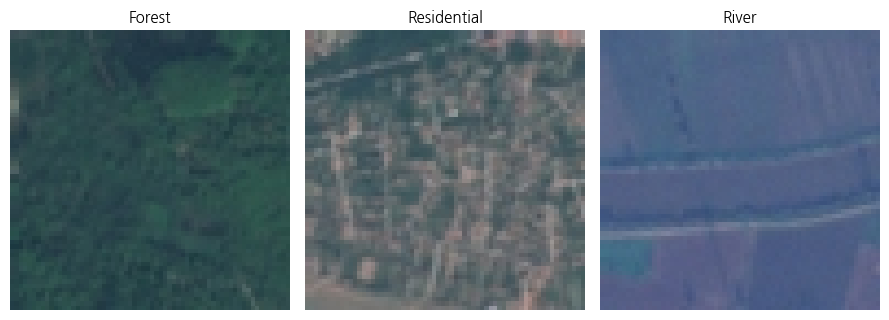

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

sample_classes = ['Forest', 'Residential', 'River']

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
for ax, cname in zip(axes.flat, sample_classes):
    class_idx = class_names.index(cname)
    idx = np.where(raw_labels_k == class_idx)[0][0]
    img = raw_images_k[idx]
    if img.max() > 1:
        img = img / 255.0
    ax.imshow(img)
    ax.set_title(cname, fontsize=11)
    ax.axis('off')
plt.tight_layout()
plt.savefig('/content/dataset_samples.jpg', dpi=150, bbox_inches='tight')
plt.show()

## 2. PyTorch CNN 불러오기 및 예측
07번 노트북과 동일한 모델 클래스를 다시 정의한 뒤, 저장해둔 가중치를 불러옵니다.

In [ ]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class CNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

PYTORCH_CNN_PATH = '/content/drive/MyDrive/pytorch_cnn_model.pt'

test_dataset_pt = datasets.ImageFolder(
    os.path.join(SPLIT_DIR, 'test'),
    transform=transforms.Compose([transforms.Resize((64, 64)), transforms.ToTensor()]))
test_loader_pt = DataLoader(test_dataset_pt, batch_size=32, shuffle=False)
class_names_pt = test_dataset_pt.classes

pytorch_model = CNN(len(class_names_pt)).to(device)
pytorch_model.load_state_dict(torch.load(PYTORCH_CNN_PATH, map_location=device))
pytorch_model.eval()

all_images, all_labels, all_probs = [], [], []
with torch.no_grad():
    for images, labels in test_loader_pt:
        images = images.to(device)
        outputs = pytorch_model(images)
        probs = torch.softmax(outputs, dim=1)
        all_images.append(images.cpu().numpy())
        all_labels.append(labels.numpy())
        all_probs.append(probs.cpu().numpy())

all_images = np.concatenate(all_images)  # (N, C, H, W)
all_labels = np.concatenate(all_labels)
all_probs = np.concatenate(all_probs)
pytorch_preds = all_probs.argmax(axis=1)

images_hwc_pt = np.transpose(all_images, (0, 2, 3, 1))  # (N, H, W, C)

print('PyTorch CNN 예측 완료. 정확도:', (pytorch_preds == all_labels).mean())

PyTorch CNN 예측 완료. 정확도: 0.937037037037037


In [ ]:
plot_confusion(all_labels, pytorch_preds, class_names_pt, 'PyTorch CNN - Confusion Matrix')

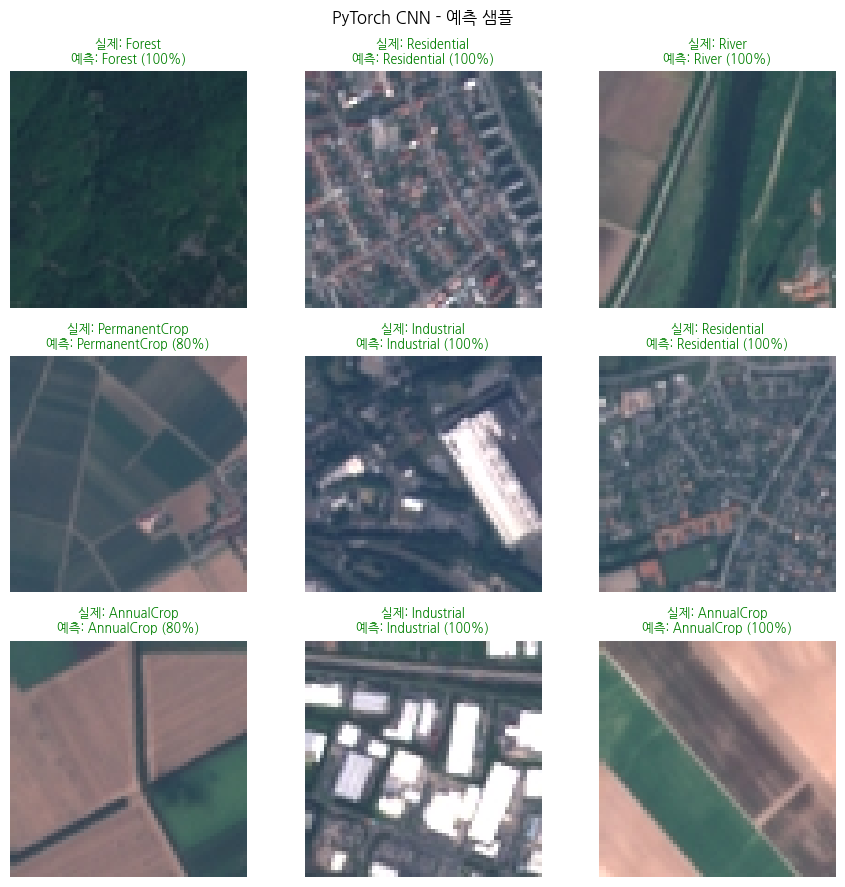

In [ ]:
plot_sample_predictions(images_hwc_pt, all_labels, pytorch_preds, all_probs, class_names_pt, 'PyTorch CNN - 예측 샘플')

## 참고
두 Confusion Matrix를 나란히 놓고 비교하면, 어떤 클래스가 두 모델 모두에서 공통으로 헷갈리는지(예: 시각적으로 비슷한 토지 유형)와
PyTorch 모델이 어떤 클래스에서 특히 더 개선되었는지를 확인할 수 있습니다.